In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import data

In [2]:
events = pd.read_parquet("data/events.parquet")
races = pd.read_parquet("data/races.parquet")
runners = pd.read_parquet("data/runners.parquet")

In [3]:
events

,location,event_date
event_id,,
1824,Bev,2019-09-24
3516,ChelmC,2019-09-24
11890,Ling,2019-09-24
21095,Warw,2019-09-24
14768,Newcastle,2026-01-10
...,...,...
13190,Muss,2017-05-04
896,Ayr,2021-08-09
17352,Ripon,2021-08-09


In [4]:
races

,race_type,race_time,distance_f,event_id
race_id,,,,
162764294,Hcap,2019-09-24 15:05:00,7,1824
162764320,Hcap,2019-09-24 17:45:00,10,1824
162764284,Nov Stks,2019-09-24 14:00:00,5,1824
162764331,Nov Stks,2019-09-24 17:25:00,7,3516
162764361,Hcap,2019-09-24 20:30:00,14,3516
...,...,...,...,...
186160695,Nov Stks,2021-08-09 15:35:00,7,896
186161070,Hcap,2021-08-09 19:55:00,5,17352
186161164,App Hcap,2021-08-09 17:35:00,6,22091


In [5]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234


# Utilities

In [6]:
nth_races = [races.sort_values("race_time").groupby("event_id").nth(i) for i in range(8)]

In [7]:
nth_runners = [runners[runners.race_id.isin(r.index)] for r in nth_races]

In [8]:
def get_favourites(runners):
    return runners.sort_values("bsp").groupby("race_id").head(1)

## Graphing

In [137]:
def plot_trade_investment(trades, title="Investment Performance", axs=None, label="", log=False):
    if axs is None:
        fig, axs = plt.subplots()
    if log:
        axs.set_yscale("log")
    if "stake" in trades:
        axs.plot(trades.race_time, trades.stake.cumsum(), label=f"Total Staked {label}")
    axs.plot(trades.race_time, trades.value, label=f"Total Value {label}")
    if axs == plt: axs.title(title)
    else: axs.set_title(title)
    axs.legend()

# General Statistics

In [10]:
nth_favourites = [get_favourites(x) for x in [runners[runners.race_id.isin(r.index)] for r in nth_races]]
all_favourites = get_favourites(runners)

## Price of the favourite

### Per Race

In [11]:
fav_stats = []
for i, f in enumerate(nth_favourites, 1):
    fav_stats.append({
        "race_no": i,
        "win_rate": f.win_lose.mean(),
        "avg_price": f.bsp.mean(),
        "implied_odds": f.implied_odds.mean()
    })
fav_stats = pd.DataFrame(fav_stats).set_index("race_no")

<Axes: xlabel='race_no'>

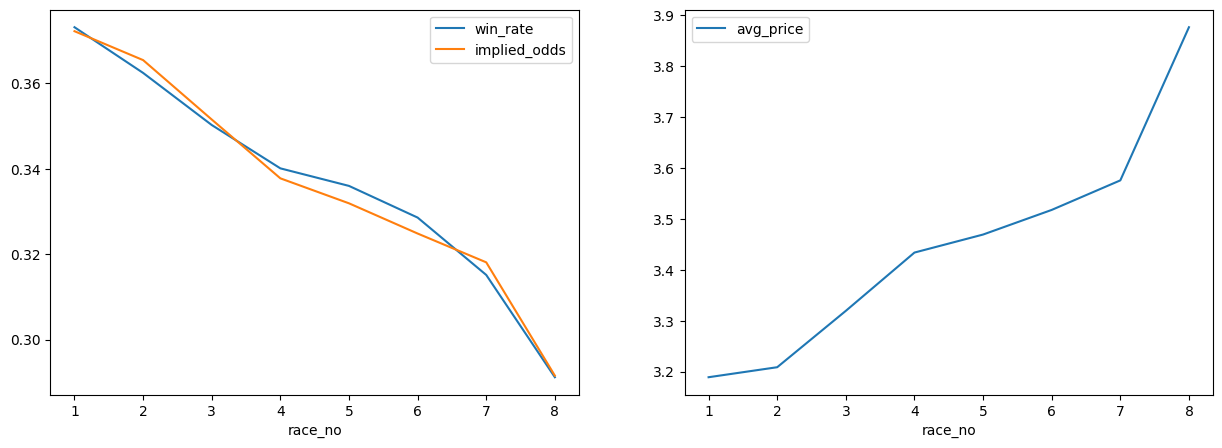

In [12]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
fav_stats.plot(y=["win_rate", "implied_odds"], ax=axs[0])
fav_stats.plot(y="avg_price", ax=axs[1])

### Over Time

In [13]:
window_size = 1000

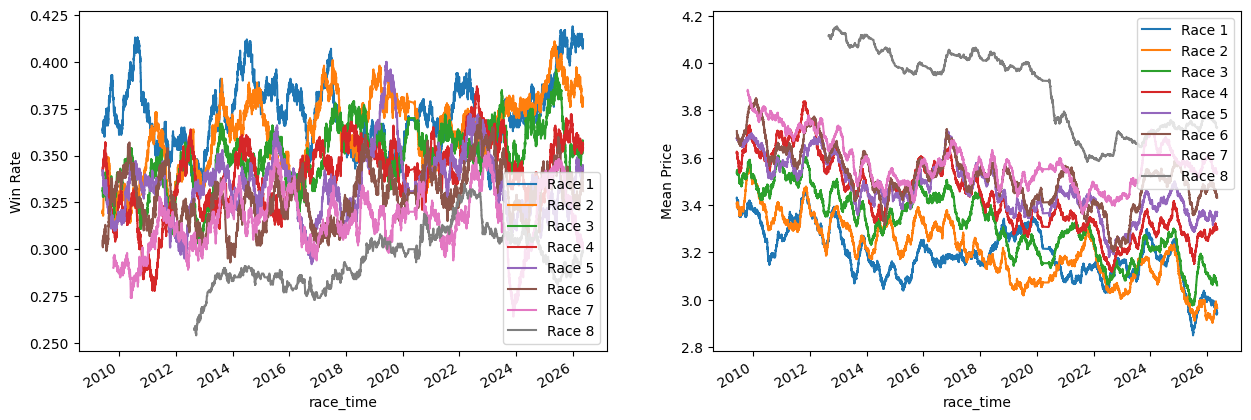

In [14]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
for i, f in enumerate(nth_favourites, 1):
    fs = f.join(races, on="race_id", how="inner").sort_values("race_time").set_index("race_time")
    #fs = f.sort_values("market_time").set_index("market_time")
    fs.win_lose.rolling(window_size).mean().plot(label=f"Race {i}", ax=axs[0])
    fs.bsp.rolling(window_size).mean().plot(label=f"Race {i}", ax=axs[1])
axs[0].set_ylabel("Win Rate")
axs[0].legend()
axs[1].set_ylabel("Mean Price")
axs[1].legend()

In [15]:
window_size=10000

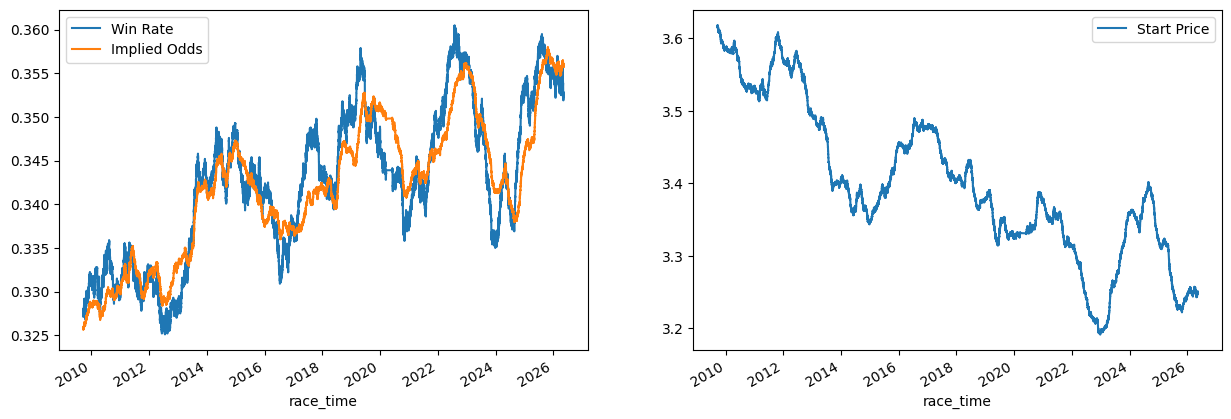

In [16]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
fs = all_favourites.join(races, on="race_id", how="inner").sort_values("race_time").set_index("race_time")
fs.win_lose.rolling(window_size).mean().plot(label="Win Rate", ax=axs[0])
fs.implied_odds.rolling(window_size).mean().plot(label="Implied Odds", ax=axs[0])
fs.bsp.rolling(window_size).mean().plot(ax=axs[1], label="Start Price")
axs[0].legend()
axs[1].legend()

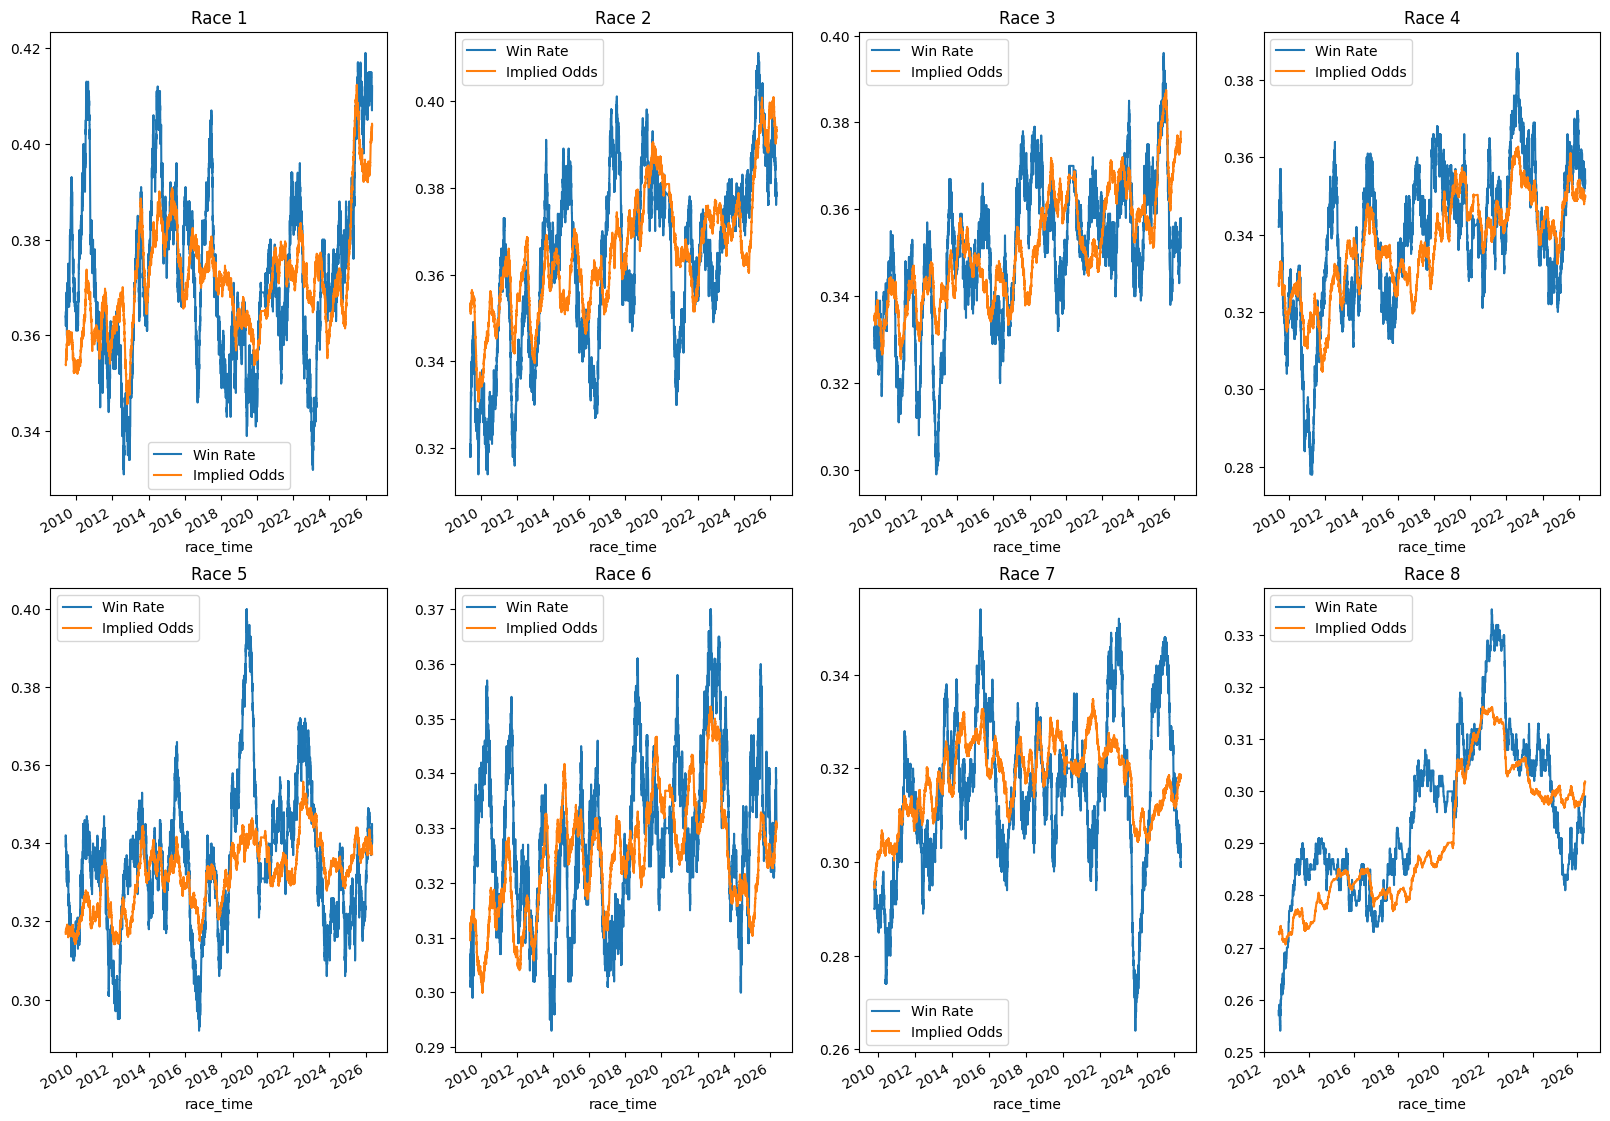

In [17]:
window_size = 1000
fig, axs = plt.subplots(2,4, figsize=(20,15))
axs = axs.flatten()
for i,f in enumerate(nth_favourites):
    f = f.join(races, on="race_id", how="inner").sort_values("race_time").set_index("race_time")
    f.win_lose.rolling(window_size).mean().plot(label="Win Rate", ax=axs[i])
    f.implied_odds.rolling(window_size).mean().plot(label="Implied Odds", ax=axs[i])
    axs[i].set_title(f"Race {i+1}")
    axs[i].legend()

## Accuracy of prices

Text(0.5, 1.0, 'Implied Odds Against Actual For All Favourites')

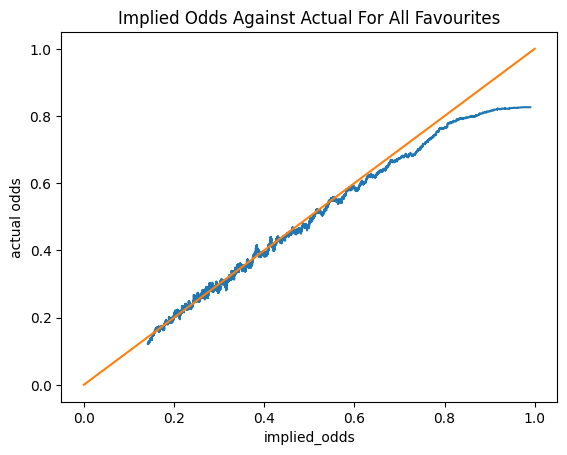

In [18]:
all_favourites.sort_values("implied_odds").set_index("implied_odds").win_lose.rolling(2000).mean().plot()
plt.ylabel("actual odds")
plt.plot([0,1],[0,1])
plt.title("Implied Odds Against Actual For All Favourites")

Text(0.5, 1.0, 'Implied Odds Against Actual For Favourites Per Race')

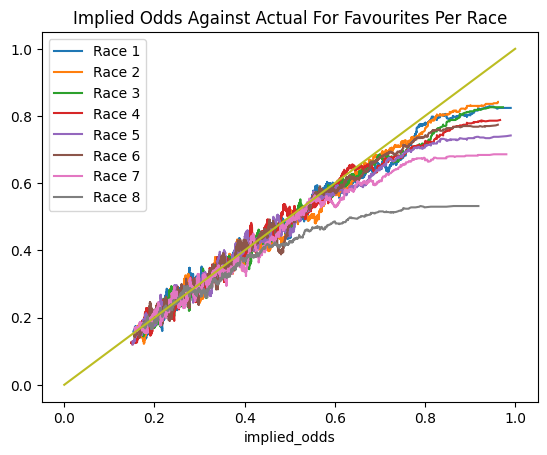

In [19]:
for i, f in enumerate(nth_favourites, 1):
    f.sort_values("implied_odds").set_index("implied_odds").win_lose.rolling(500).mean().plot(label=f"Race {i}")
plt.legend()
plt.plot([0,1],[0,1])
plt.title("Implied Odds Against Actual For Favourites Per Race")

# Define strategies

### Utilities

In [45]:
def action_trades(trades, mode="absolute"):
    trades = trades.join(races, on="race_id", how="inner").sort_values("race_time")

    if mode == "absolute":
        t = trades.assign(profit=(trades.bsp * trades.win_lose -1)*trades.stake)
        return t.assign(value=t.profit.cumsum())
    elif mode == "percentage":
        back = ((trades.bsp)*trades.percentage_stake*trades.win_lose) -trades.percentage_stake
        lay =  trades.percentage_liability * ((1 - trades.win_lose)/(trades.bsp-1) - trades.win_lose)

        t = trades.assign(percentage_profit=back+lay)
        t = t.assign(value=(t.percentage_profit+1).cumprod())
        return t
    else:
        raise ValueError("Mode invalid")

In [20]:
def action_trades(trades):
    t = trades.assign(profit=(trades.bsp * trades.win_lose -1)*trades.stake)
    return t.assign(value=t.profit.cumsum())

In [21]:
def action_trades_percentage(trades):
    trades = trades.join(races, on="race_id", how="inner").sort_values("race_time")
    #trades = trades.assign("race_time", races[trades.race_id].race_time).sort_values("race_time")
    back = ((trades.bsp)*trades.percentage_stake*trades.win_lose) -trades.percentage_stake
    lay =  trades.percentage_liability * ((1 - trades.win_lose)/(trades.bsp-1) - trades.win_lose)
    
    #back = ((trades.bsp-1)*trades.percentage_stake) * trades.win_lose + \
    #        -trades.percentage_stake * (not trades.win_lose)
    #lay  = ((trades.percentage_liability/(trades.bsp-1)) * (not trades.win_lose)) + \
    #        -trades.percentage_liability * trades.win_lose
    
    t = trades.assign(percentage_profit=back+lay)
    #t = trades.assign(stake = trades.iloc[1:] 
    t = t.assign(value=(t.percentage_profit+1).cumprod())
    return t

In [22]:
nth_runners[0]

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.0,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.0,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24599181,162764326,Dark Side Prince,False,480.656150,0.002080,469.601990,159.057159,640.0,130.00,1000.0,410.00,8.100000,1082.969971,39.290001
26182112,162764326,Tiger Balm,False,40.000000,0.025000,51.434792,68.449791,100.0,36.00,1000.0,48.00,8.400000,3769.439941,191.369995
20491299,162764446,Pytilia,True,6.000000,0.166667,6.348462,7.530416,9.0,5.50,12.0,1.01,9081.700195,84160.281250,52529.238281
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25105916,186160680,Glorious Rio,False,3.550000,0.281690,3.692944,3.779581,4.1,3.22,1000.0,1.33,3792.659912,95581.296875,12147.580078
33068756,186161205,Golden Cluster,False,65.625175,0.015238,46.086895,42.700008,130.0,28.00,180.0,60.00,604.400024,4080.879883,201.330002
36110949,186161205,Tommytwohoots,False,2.500000,0.400000,2.619051,3.533773,4.0,2.42,940.0,2.22,11342.740234,148627.125000,18044.779297


In [23]:
def create_timeline(trades): # Takes a DataFrame of trades and aligns them with market times to use for analysis
    return trades
    #return trades.merge(races, on="race_id").sort_values("race_time")

## Betting on the favourite
The strategy simply bets one unit on the favourite for every race.

In [42]:
def bet_on_favourite(runners):
    favs = get_favourites(runners)
    trades = favs[["bsp", "win_lose", "race_id", "selection_name", "implied_odds"]].assign(stake=1)
    return action_trades(trades)

## Hedging on the favourite
Similar to the previous strategy, but stakes are altered to adjust for implied risk. Stake is sized such that a succesful bet wins one unit.

In [43]:
def hedge_on_favourite(runners):
    favs = get_favourites(runners)
    trades = favs[["bsp", "win_lose", "race_id", "selection_name", "implied_odds"]].assign(stake=favs.implied_odds)
    return action_trades(trades)

## Learning Based Kelly-Criterion

This strategy involves looking at the likelihood of winning to inform the size of the bet.

$$f^* = p-\frac{q}{b}$$

In [109]:
def bet_kelly(runners, window_size=300, bet_size=0.005, back=True, lay=True):
    favs = get_favourites(runners)#.sort_values("market_time")
    p = favs.win_lose.rolling(window_size).mean()
    q = 1-p
    b = favs.bsp - 1
    #print(p[~p.isna()])
    trades = favs[["bsp", "win_lose", "race_id", "selection_name"]]
    trades = trades.assign(percentage_stake=p-q/b if back else 0)
    trades = trades.assign(percentage_liability=q-p/b if lay else 0)
    trades = trades[~trades.percentage_stake.isna() | ~trades.percentage_liability.isna()]
    trades.percentage_stake = trades.percentage_stake.clip(lower=0) * bet_size
    trades.percentage_liability = trades.percentage_liability.clip(lower=0) * bet_size
    #trades = trades[(trades.percentage_stake > 0) | (trades.percentage_liability > 0)]
    #trades.percentage_stake=0.4-trades.percentage_stake
    #trades = trades[trades.
    return action_trades(trades, mode="percentage")

# Analysis

## Betting on the favourite

In [46]:
nth_trades = [bet_on_favourite(runners[runners.race_id.isin(m.index)]) for m in nth_races]
all_trades = bet_on_favourite(runners)

In [47]:
all_trades

,bsp,win_lose,race_id,selection_name,implied_odds,stake,race_type,race_time,distance_f,event_id,profit,value
selection_id,,,,,,,,,,,,
1129962,3.384183,False,21179929,Elite Land,0.295492,1,Hcap,2008-09-01 13:50:00,13,7237,-1.000000,-1.000000
2786498,4.100000,True,21179961,Circadian Rhythm,0.243902,1,Hcap,2008-09-01 14:10:00,8,10894,3.100000,2.100000
3105499,2.678090,True,21179931,Scenic Pass,0.373400,1,Claim Stks,2008-09-01 14:20:00,6,7237,1.678090,3.778090
3099701,5.298158,False,21179945,Claphands,0.188745,1,Nursery,2008-09-01 14:30:00,5,9006,-1.000000,2.778090
2178483,3.416365,False,21179963,Apache Fort,0.292709,1,Hcap,2008-09-01 14:40:00,12,10894,-1.000000,1.778090
...,...,...,...,...,...,...,...,...,...,...,...,...
84484375,4.696784,True,257930827,Son Of Tyran,0.212912,1,Nov Hcap Hrd,2026-05-10 14:52:00,24,12625,3.696784,941.375034
18834015,2.360000,False,257930833,Nazare,0.423729,1,Hcap Chs,2026-05-10 15:27:00,24,12625,-1.000000,940.375034
3216291,2.479131,True,257930844,Pergamon,0.403367,1,Hcap Hrd,2026-05-10 16:02:00,16,12625,1.479131,941.854165


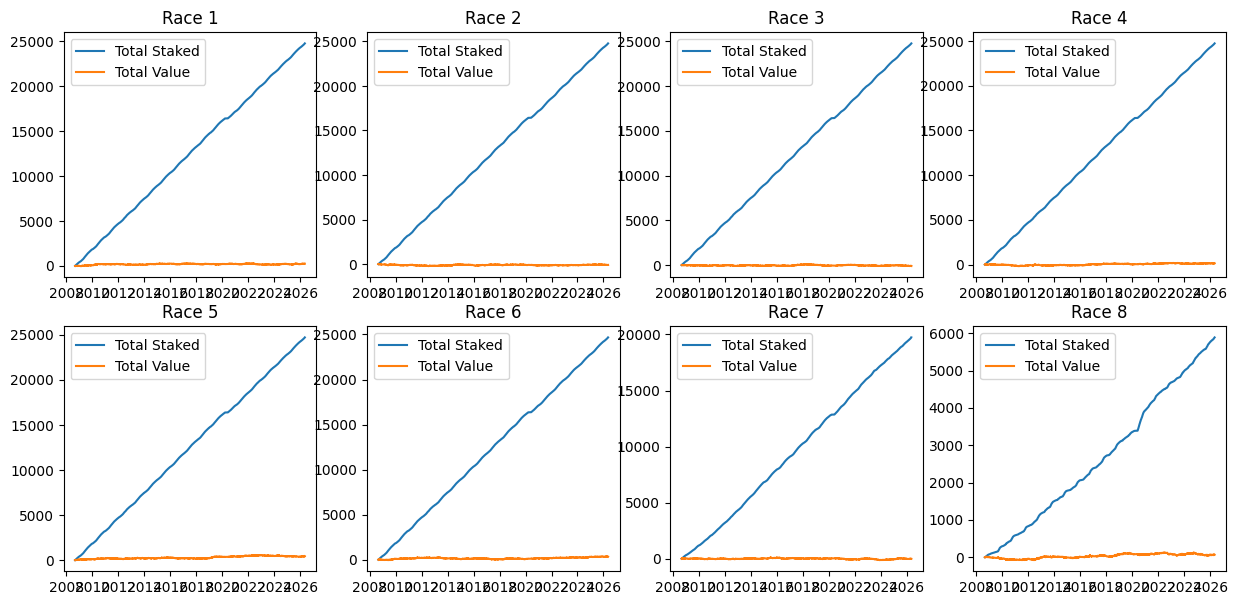

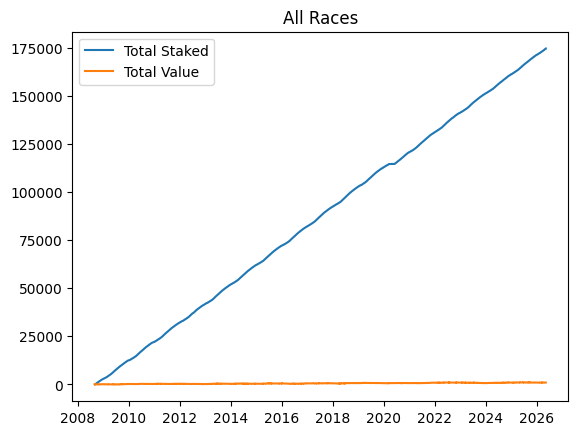

In [48]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i])
plt.show()
plot_trade_investment(all_trades, "All Races")

## Hedging on the favourite

In [49]:
nth_trades = [hedge_on_favourite(runners[runners.race_id.isin(m.index)]) for m in nth_races]
all_trades = hedge_on_favourite(runners)

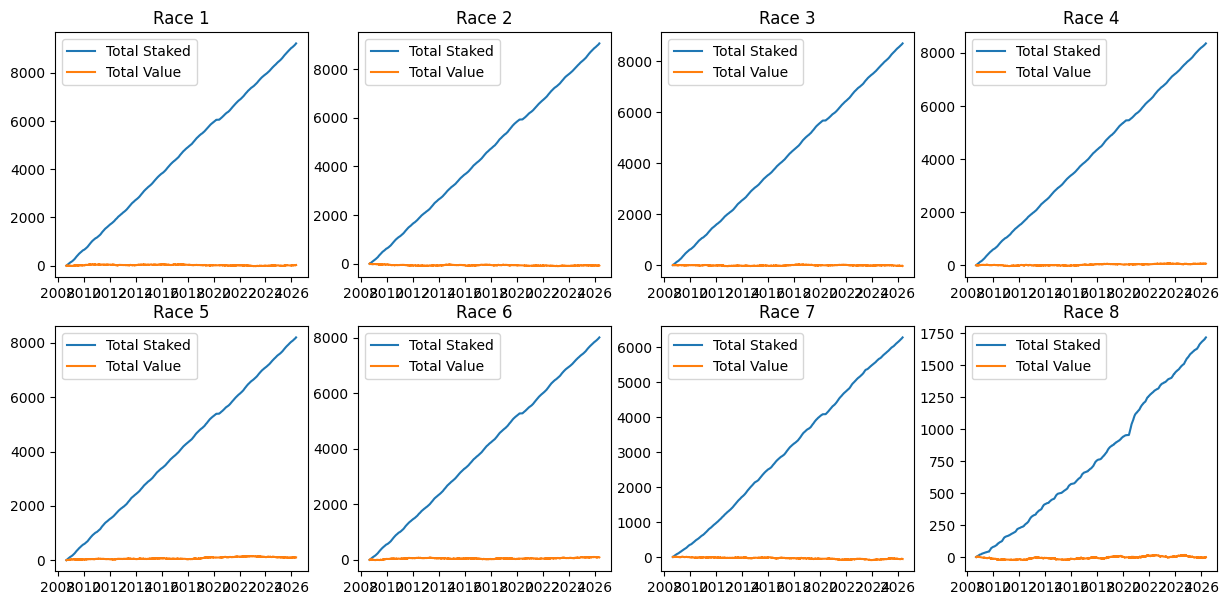

In [50]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i]) 

## Learning Kelly

In [113]:
nth_trades = [bet_kelly(m, bet_size=0.01*8, lay=False) for m in nth_runners]
all_trades = bet_kelly(runners, bet_size=0.01, lay=False)

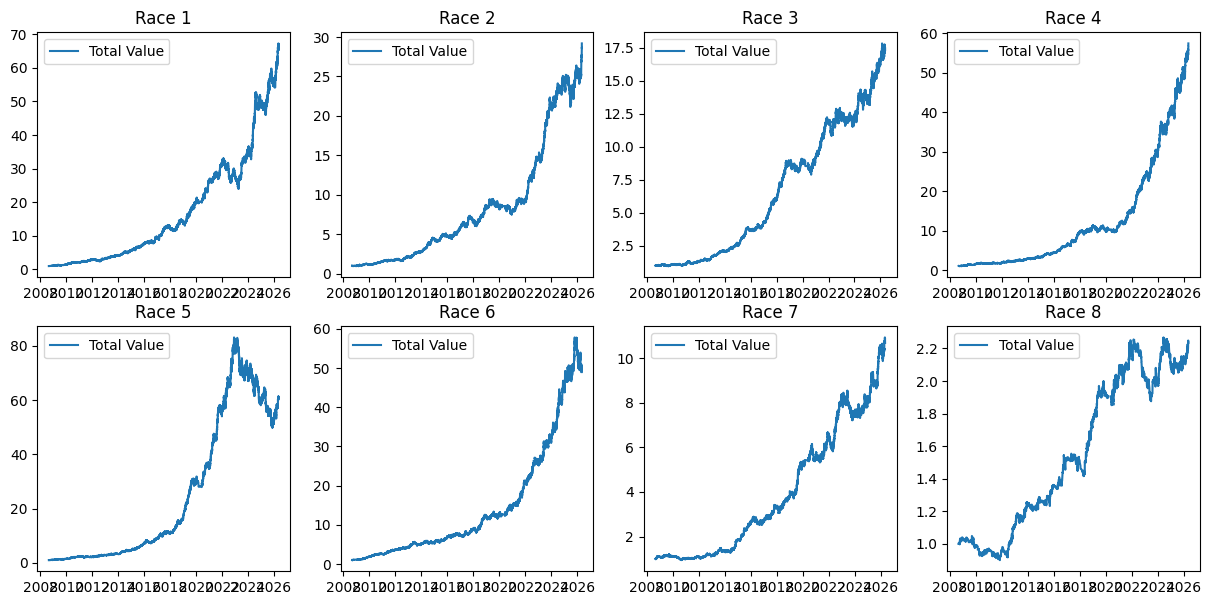

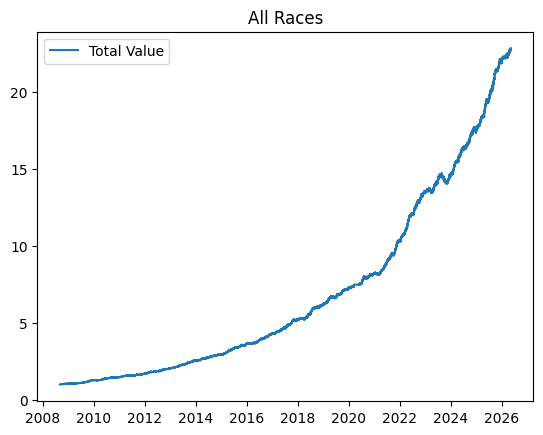

In [114]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i])
plt.show()
plot_trade_investment(all_trades, "All Races")

In [112]:
all_trades

,bsp,win_lose,race_id,selection_name,percentage_stake,percentage_liability,race_type,race_time,distance_f,event_id,percentage_profit,value
selection_id,,,,,,,,,,,,
1129962,3.384183,False,21179929,Elite Land,0.000000,0.0,Hcap,2008-09-01 13:50:00,13,7237,0.000000,1.000000
2786498,4.100000,True,21179961,Circadian Rhythm,0.000000,0.0,Hcap,2008-09-01 14:10:00,8,10894,0.000000,1.000000
3105499,2.678090,True,21179931,Scenic Pass,0.000021,0.0,Claim Stks,2008-09-01 14:20:00,6,7237,0.000036,1.000036
3099701,5.298158,False,21179945,Claphands,0.000000,0.0,Nursery,2008-09-01 14:30:00,5,9006,0.000000,1.000036
2178483,3.416365,False,21179963,Apache Fort,0.000053,0.0,Hcap,2008-09-01 14:40:00,12,10894,-0.000053,0.999983
...,...,...,...,...,...,...,...,...,...,...,...,...
84484375,4.696784,True,257930827,Son Of Tyran,0.000005,0.0,Nov Hcap Hrd,2026-05-10 14:52:00,24,12625,0.000018,1.368883
18834015,2.360000,False,257930833,Nazare,0.000034,0.0,Hcap Chs,2026-05-10 15:27:00,24,12625,-0.000034,1.368837
3216291,2.479131,True,257930844,Pergamon,0.000017,0.0,Hcap Hrd,2026-05-10 16:02:00,16,12625,0.000025,1.368871


In [77]:
def sharpe_ratio(trades):
    average_return = trades.percentage_profit.mean()
    std = trades.percentage_profit.std()

    per_bet = average_return/std
    annualised = per_bet * np.sqrt(trades.count().max() / ((trades.race_time.max()-trades.race_time.min()) / pd.Timedelta(days=365.25)))

    return average_return/std, annualised

In [116]:
sharpe_ratio(all_trades)

(np.float64(0.04099588420931733), np.float64(4.075295149995348))

In [117]:
[sharpe_ratio(x) for x in nth_trades]

[(np.float64(0.04225504001000575), np.float64(1.581671008234059)),
 (np.float64(0.036414478684200745), np.float64(1.3628294333385078)),
 (np.float64(0.035461734773147485), np.float64(1.3267167246523774)),
 (np.float64(0.04202866348711208), np.float64(1.5717670808819657)),
 (np.float64(0.04308835717580986), np.float64(1.610679805047139)),
 (np.float64(0.03955030152373843), np.float64(1.4772570308808122)),
 (np.float64(0.03457237843460221), np.float64(1.1550460048048452)),
 (np.float64(0.0376418451960663), np.float64(0.6869700025485121))]

In [115]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234


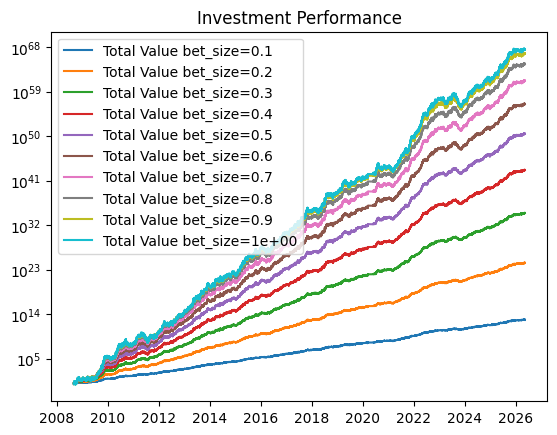

In [141]:
fig, ax = plt.subplots()
for x in np.arange(0.1, 1.1, 0.1):
    all_trades = bet_kelly(runners, bet_size=x, lay=False)
    plot_trade_investment(all_trades, axs=ax, label=f"bet_size={x:.0}", log=True)

In [142]:
t = bet_kelly(runners, bet_size=1, lay=False)

In [148]:
t.set_index("race_time").resample("YE").last().value.pct_change().mean()

np.float64(3640053.958553277)